In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from sentence_transformers import SentenceTransformer

DATA = "../data/"
CHARTS = "../charts/"
BLUE = "#2a6f97"
GREY = "#b8c4ce"

news = pd.read_pickle(DATA + "news_clean.pkl").reset_index(drop=True)
news["text"] = news["title"] + ". " + news["abstract"]

print(f"Search archive: {len(news):,} articles")

W1025 12:59:25.871000 86930 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Search archive: 51,282 articles


In [2]:
queries = [
    # Direct, keyword-style searches
    {"id": 1,  "type": "Direct",  "query": "impeachment inquiry hearings"},
    {"id": 2,  "type": "Direct",  "query": "California wildfires"},
    {"id": 3,  "type": "Direct",  "query": "NFL quarterback injury"},
    {"id": 4,  "type": "Direct",  "query": "Thanksgiving recipes"},
    {"id": 5,  "type": "Direct",  "query": "stock market record high"},
    {"id": 6,  "type": "Direct",  "query": "electric cars"},
    {"id": 7,  "type": "Direct",  "query": "royal family"},
    # Natural, everyday-language questions
    {"id": 8,  "type": "Natural", "query": "What happened with the President and Ukraine?"},
    {"id": 9,  "type": "Natural", "query": "How can I lose weight without dieting?"},
    {"id": 10, "type": "Natural", "query": "Which celebrities died recently?"},
    {"id": 11, "type": "Natural", "query": "Is it going to be freezing cold this week?"},
    {"id": 12, "type": "Natural", "query": "Cheap places to go on vacation"},
    {"id": 13, "type": "Natural", "query": "How do I save more money for retirement?"},
    {"id": 14, "type": "Natural", "query": "Is now a good time to buy a house?"},
    {"id": 15, "type": "Natural", "query": "Tips for sleeping better at night"},
]

queries_df = pd.DataFrame(queries).set_index("id")
queries_df

,type,query
id,,
1,Direct,impeachment inquiry hearings
2,Direct,California wildfires
3,Direct,NFL quarterback injury
4,Direct,Thanksgiving recipes
5,Direct,stock market record high
6,Direct,electric cars
7,Direct,royal family
8,Natural,What happened with the President and Ukraine?
9,Natural,How can I lose weight without dieting?


In [3]:
tfidf = TfidfVectorizer(stop_words="english", sublinear_tf=True)
tfidf_matrix = tfidf.fit_transform(news["text"])

def keyword_search(query, k=5):
    scores = linear_kernel(tfidf.transform([query]), tfidf_matrix).ravel()
    top = np.argsort(-scores)[:k]
    top = [i for i in top if scores[i] > 0]   # no matching words = no result
    return news.loc[top, "news_id"].tolist()

print("Keyword search ready. Vocabulary size:", len(tfidf.vocabulary_))

Keyword search ready. Vocabulary size: 54666


In [4]:
model = SentenceTransformer("all-MiniLM-L6-v2")
EMB = DATA + "embeddings_minilm.npy"

if os.path.exists(EMB):
    emb = np.load(EMB)
    print("Loaded saved embeddings.")
else:
    emb = model.encode(news["text"].tolist(), batch_size=128,
                       show_progress_bar=True, normalize_embeddings=True)
    np.save(EMB, emb)
    print("Created and saved embeddings.")

assert len(emb) == len(news)

def semantic_search(query, k=5):
    q = model.encode([query], normalize_embeddings=True)[0]
    top = np.argsort(-(emb @ q))[:k]
    return news.loc[top, "news_id"].tolist()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/401 [00:00<?, ?it/s]

Created and saved embeddings.


In [5]:
rows = []
times = {"keyword": [], "semantic": []}

for q in queries:
    for method, search in [("keyword", keyword_search), ("semantic", semantic_search)]:
        start = time.perf_counter()
        ids = search(q["query"])
        times[method].append(time.perf_counter() - start)
        for rank, nid in enumerate(ids, start=1):
            rows.append({"query_id": q["id"], "method": method, "rank": rank, "news_id": nid})

results = pd.DataFrame(rows)
results.to_csv(DATA + "search_results.csv", index=False)

for m, t in times.items():
    print(f"{m:9s}: {len(results[results.method == m])} results, "
          f"average search time {np.mean(t) * 1000:.0f} ms")

keyword  : 75 results, average search time 13 ms
semantic : 75 results, average search time 258 ms


In [6]:
articles = news.set_index("news_id")[["title", "abstract"]]

sheet = (results[["query_id", "news_id"]]
         .drop_duplicates()
         .join(queries_df["query"], on="query_id")
         .join(articles, on="news_id")
         .sample(frac=1, random_state=42)          # shuffle
         .sort_values("query_id", kind="stable"))  # group by question, order stays shuffled

sheet["abstract"] = sheet["abstract"].str.slice(0, 200)
sheet["relevant"] = ""
sheet = sheet[["query_id", "query", "news_id", "title", "abstract", "relevant"]]
sheet.to_csv(DATA + "judging_sheet.csv", index=False)

print(f"{len(sheet)} articles to judge (articles found by both methods appear only once)")

138 articles to judge (articles found by both methods appear only once)


In [9]:
mine = pd.read_csv(DATA + "judgments.csv")
claude = pd.read_csv(DATA + "claude_judgments.csv")
print("Columns in judgments.csv:", mine.columns.tolist())

comp = mine[["query_id", "query", "news_id", "title", "relevant"]].merge(
    claude[["query_id", "news_id", "relevant", "borderline_note"]],
    on=["query_id", "news_id"], suffixes=("_me", "_claude"))
agreement = (comp["relevant_me"] == comp["relevant_claude"]).mean()
print(f"Agreement between the two judges: {agreement:.0%}")
comp[comp["relevant_me"] != comp["relevant_claude"]][["query", "title", "relevant_me", "relevant_claude", "borderline_note"]]

Columns in judgments.csv: ['query_id', 'query', 'news_id', 'title', 'abstract', 'relevant', 'borderline_note']
Agreement between the two judges: 100%


,query,title,relevant_me,relevant_claude,borderline_note


In [10]:
review = pd.read_csv(DATA + "judgments.csv")
review[review["borderline_note"].notna()][["query", "title", "relevant", "borderline_note"]]


,query,title,relevant,borderline_note
4,impeachment inquiry hearings,"Nunes calls impeachment inquiry ""carefully orc...",1,Reaction to the inquiry rather than the hearin...
16,California wildfires,"World Series Game 7, California wildfires: 5 t...",0,Daily news roundup; wildfires are only one of ...
19,NFL quarterback injury,Report: Broncos WR Emmanuel Sanders 'doesn't a...,0,"Injury story, but a wide receiver, not a quart..."
20,NFL quarterback injury,Bears' Danny Trevathan Suffers Gruesome Elbow ...,0,"Injury story, but a linebacker, not a quarterback"
21,NFL quarterback injury,"NFL injury report roundup, Week 10",0,General league injury roundup; quarterbacks ar...
22,NFL quarterback injury,Buccaneers-Seahawks Thursday injury report,0,General team injury report
27,NFL quarterback injury,Top 10 NFL quarterbacks heading into Week 10,0,"About quarterbacks, but rankings, not injuries"
39,stock market record high,"Stock up, stock down: Bears-Chargers",0,Football article; 'stock' used in a different ...
40,stock market record high,Over the past seven decades this has been th...,1,Explains the current record-setting rally with...
44,stock market record high,Strong stock market may hide problems with you...,0,Record high is only the context; main topic is...


In [11]:
judg = pd.read_csv(DATA + "judgments.csv")[["query_id", "news_id", "relevant"]]
scored = results.merge(judg, on=["query_id", "news_id"], how="left")
assert scored["relevant"].notna().all(), "Some results haven't been judged yet."

useful = (scored.groupby(["query_id", "method"])["relevant"].sum()
          .unstack("method").reindex(queries_df.index).fillna(0))
useful = useful.join(queries_df[["type", "query"]])

summary = pd.DataFrame({
    "Useful results in top 5 (all questions)": useful[["keyword", "semantic"]].mean(),
    "Direct questions": useful[useful.type == "Direct"][["keyword", "semantic"]].mean(),
    "Natural questions": useful[useful.type == "Natural"][["keyword", "semantic"]].mean(),
    "Questions with zero useful results": (useful[["keyword", "semantic"]] == 0).sum(),
    "Average search time (ms)": pd.Series({m: np.mean(t) * 1000 for m, t in times.items()}),
}).T.round(2)
summary

,keyword,semantic
Useful results in top 5 (all questions),2.67,3.60
Direct questions,3.29,4.00
Natural questions,2.12,3.25
Questions with zero useful results,2.00,0.00
Average search time (ms),12.53,258.43


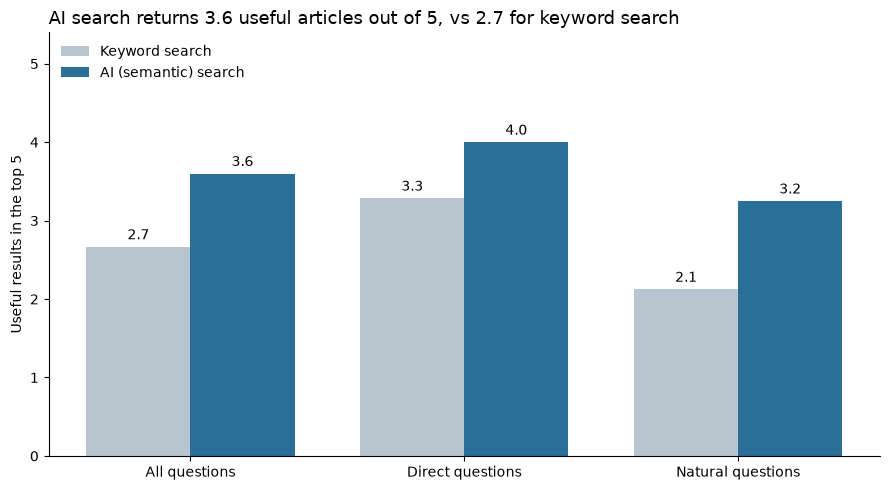

In [12]:
groups = ["All questions", "Direct questions", "Natural questions"]
kw = [useful["keyword"].mean(),
      useful[useful.type == "Direct"]["keyword"].mean(),
      useful[useful.type == "Natural"]["keyword"].mean()]
se = [useful["semantic"].mean(),
      useful[useful.type == "Direct"]["semantic"].mean(),
      useful[useful.type == "Natural"]["semantic"].mean()]

x = np.arange(len(groups))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - w/2, kw, w, color=GREY, label="Keyword search")
b2 = ax.bar(x + w/2, se, w, color=BLUE, label="AI (semantic) search")
ax.bar_label(b1, labels=[f"{v:.1f}" for v in kw], padding=3)
ax.bar_label(b2, labels=[f"{v:.1f}" for v in se], padding=3)
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylim(0, 5.4)
ax.set_ylabel("Useful results in the top 5")
ax.legend(frameon=False, loc="upper left")
ax.set_title(f"AI search returns {se[0]:.1f} useful articles out of 5, "
             f"vs {kw[0]:.1f} for keyword search", loc="left", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(CHARTS + "07_search_comparison.png", dpi=150)
plt.show()

In [13]:
useful["difference"] = useful["semantic"] - useful["keyword"]
ex_id = useful["difference"].idxmax()
print("Example question:", queries_df.loc[ex_id, "query"])

articles = news.set_index("news_id")[["title", "abstract"]]
ex = scored[scored.query_id == ex_id].join(articles["title"], on="news_id")

def mark(df):
    return (df.sort_values("rank")
              .apply(lambda r: f"{'✓' if r.relevant else '✗'} {r.title}", axis=1)
              .reset_index(drop=True))

side = pd.DataFrame({
    "Keyword search": mark(ex[ex.method == "keyword"]),
    "AI (semantic) search": mark(ex[ex.method == "semantic"]),
}).reindex(range(5)).fillna("(no result)")
side.index = side.index + 1
side

Example question: stock market record high


,Keyword search,AI (semantic) search
1,✗ Strong stock market may hide problems with y...,"✓ Stocks close at record highs on earnings, tr..."
2,✗ How the stock market works,"✓ Dow tops 28,000 for first time, capping 4-we..."
3,✓ Over the past seven decades this has been ...,✓ Dow posts another record close on strong eco...
4,"✗ Stock up, stock down in Colts' loss to Dolphins",✗ Strong stock market may hide problems with y...
5,"✗ Stock up, stock down: Bears-Chargers",✓ Over the past seven decades this has been ...


In [14]:
wins = (useful["semantic"] > useful["keyword"]).sum()
ties = (useful["semantic"] == useful["keyword"]).sum()
losses = (useful["semantic"] < useful["keyword"]).sum()
print(f"AI search better: {wins} questions | Equal: {ties} | Keyword better: {losses}")

useful[["type", "query", "keyword", "semantic"]].astype({"keyword": int, "semantic": int})

AI search better: 8 questions | Equal: 4 | Keyword better: 3


,type,query,keyword,semantic
id,,,,
1,Direct,impeachment inquiry hearings,5,5
2,Direct,California wildfires,4,5
3,Direct,NFL quarterback injury,2,1
4,Direct,Thanksgiving recipes,5,5
5,Direct,stock market record high,1,4
6,Direct,electric cars,1,3
7,Direct,royal family,5,5
8,Natural,What happened with the President and Ukraine?,5,4
9,Natural,How can I lose weight without dieting?,3,2
